## Loading in Census data for household heating source

In [17]:
import pandas as pd

#import requests to be able to pass in the census API key and access the data
import requests

# 1. define census API key and census endpoint for 2022 ACS 5-year tract data (2022 is most recent)
api_key = "f33094cc5c703bb7fc5d634e5469bbd5e3781c5d"
url = f"https://api.census.gov/data/2022/acs/acs5?get=NAME,B25040_001E,B25040_002E,B25040_004E&for=tract:*&in=state:06&key={api_key}"
response = requests.get(url)

# 2. check if the request was successful
if response.status_code == 200:
    data = response.json()
    
    #the first row contains the column headers, the rest are data rows
    headers = data[0]
    rows = data[1:]
    
    #convert into a Pandas DataFrame
    df_housing = pd.DataFrame(rows, columns=headers)
    
    #create the standard 11-digit GEOID (state + county + tract) --> need this in order to match with CDC health data later on
    df_housing['GEOID'] = df_housing['state'] + df_housing['county'] + df_housing['tract']
    
    #rename columns for readability
    df_housing = df_housing.rename(columns={
        'B25040_001E': 'total_units',
        'B25040_002E': 'utility_gas_units',
        'B25040_004E': 'electricity_units'
    })

    #quick print statement to display number of tracts
    print(f"Successfully downloaded housing data for {len(df_housing)} tracts!")
    display(df_housing.head())

#print error statement if above code doesn't work
else:
    print(f"Error fetching data: {response.status_code}")
    print(response.text)

Successfully downloaded housing data for 9129 tracts!


,NAME,total_units,utility_gas_units,electricity_units,state,county,tract,GEOID
0,Census Tract 4001; Alameda County; California,1377,1240,109,06,001,400100,06001400100
1,Census Tract 4002; Alameda County; California,876,676,157,06,001,400200,06001400200
2,Census Tract 4003; Alameda County; California,2638,1936,702,06,001,400300,06001400300
3,Census Tract 4004; Alameda County; California,1760,1324,341,06,001,400400,06001400400
4,Census Tract 4005; Alameda County; California,1679,1235,302,06,001,400500,06001400500


## Loading in CDC Places Asthma Data

In [18]:
# 1. get CDC PLACES asthma data for CA
places_url = "https://data.cdc.gov/resource/shc3-fzig.csv?stateabbr=CA&$limit=10000"

#convert into a dataframe
df_health = pd.read_csv(places_url)

#print out column names to inspect how they are capitalized
print("\nAvailable columns in health dataset:")
print(df_health.columns.tolist())

# 2. find correct FIPS column (handles both 'TractFIPS' and 'tractfips') --> need to standardize and fix capitalization discrepancies
fips_col = [col for col in df_health.columns if col.lower() == 'tractfips']

if fips_col:
    fips_column_name = fips_col[0]
    print(f"\nFound tract identifier column: '{fips_column_name}'")
    
    #standardize to 11-digit GEOID string --> need to match housing data in order to merge later on
    df_health['GEOID'] = df_health[fips_column_name].astype(str).str.zfill(11)
    
    #identify asthma prevalence column 
    asthma_col = [col for col in df_health.columns if 'casthma' in col.lower() and 'crudeprev' in col.lower()]
    target_asthma = asthma_col[0] if asthma_col else 'CASTHMA_CrudePrev'
    print(f"Using asthma prevalence column: '{target_asthma}'")
    
    #keep essential columns
    cols_to_keep = ['GEOID', target_asthma]
    if 'TotalPopulation' in df_health.columns:
        cols_to_keep.append('TotalPopulation')
        
    df_health_clean = df_health[cols_to_keep].copy()
    if target_asthma != 'CASTHMA_CrudePrev':
        df_health_clean = df_health_clean.rename(columns={target_asthma: 'CASTHMA_CrudePrev'})
else:
    print("\nError: Could not locate a tract FIPS column. Please check the printed column list above.")


Available columns in health dataset:
['stateabbr', 'statedesc', 'countyname', 'countyfips', 'tractfips', 'totalpopulation', 'access2_crudeprev', 'access2_crude95ci', 'arthritis_crudeprev', 'arthritis_crude95ci', 'binge_crudeprev', 'binge_crude95ci', 'bphigh_crudeprev', 'bphigh_crude95ci', 'bpmed_crudeprev', 'bpmed_crude95ci', 'cancer_crudeprev', 'cancer_crude95ci', 'casthma_crudeprev', 'casthma_crude95ci', 'cervical_crudeprev', 'cervical_crude95ci', 'chd_crudeprev', 'chd_crude95ci', 'checkup_crudeprev', 'checkup_crude95ci', 'cholscreen_crudeprev', 'cholscreen_crude95ci', 'colon_screen_crudeprev', 'colon_screen_crude95ci', 'copd_crudeprev', 'copd_crude95ci', 'corem_crudeprev', 'corem_crude95ci', 'corew_crudeprev', 'corew_crude95ci', 'csmoking_crudeprev', 'csmoking_crude95ci', 'dental_crudeprev', 'dental_crude95ci', 'depression_crudeprev', 'depression_crude95ci', 'diabetes_crudeprev', 'diabetes_crude95ci', 'ghlth_crudeprev', 'ghlth_crude95ci', 'highchol_crudeprev', 'highchol_crude95ci',

## Merge datasets together into one dataframe

In [3]:
#merge housing data and asthma prevalence data

merged_df = pd.merge(df_housing, df_health_clean, on='GEOID', how='inner')

display(merged_df.head())
    
#save as csv as well
merged_df.to_csv("ca_heating_vs_asthma_tracts.csv", index=False)

,NAME,total_units,utility_gas_units,electricity_units,state,county,tract,GEOID,CASTHMA_CrudePrev
0,Census Tract 4001; Alameda County; California,1377,1240,109,06,001,400100,06001400100,8.2
1,Census Tract 4002; Alameda County; California,876,676,157,06,001,400200,06001400200,8.5
2,Census Tract 4003; Alameda County; California,2638,1936,702,06,001,400300,06001400300,9.3
3,Census Tract 4004; Alameda County; California,1760,1324,341,06,001,400400,06001400400,9.5
4,Census Tract 4005; Alameda County; California,1679,1235,302,06,001,400500,06001400500,9.9


## Summary of work so far

### Overview 
So far, we have loaded in two main datasets: the ACS Table B25040 House Heating Fuel dataset from the official U.S. Census Bureau website and the CDC PLACES Asthma Data dataset from the CDC PLACES Data Portal. The links to these two portals are: 

* https://data.census.gov
* https://www.cdc.gov/places/index.html

### Quick breakdown

#### ACS Table B25040 House Heating Fuel Dataset

This dataset provides survey data collected at the neighborhood level detailing physical characteristics of residential homes. 

It gives us the counts of housing units for different primary heating fuel types, like utility gas versus electric. 

This data is important for this research becasue it serves as our independent variable. We want to see if having gas heating vs electric or some other source has any impacts on health outcomes. So this data will allow us to calculate what percentage of homes in a given neighborhood rely on gas vs. electric. We can then compare those percentages with asthma prevalance in different neighborhoods and see if there is any correlation (once we control for other variables/confounders)

#### CDC PLACES Dataset

This dataset is a model-based public health estimate dataset published by the CDC. The data is derived from Behavioral Risk Factor Surveillance System data, Census population data, and American Community Survey data. They use a small area estimate (SAE) approach, combining multilevel regression and poststratification to get estimates for each census tract. Methodology source: https://www.cdc.gov/places/methodology/index.html 

It gives us modeled neighborhood-level prevalence rates for specific medical conditions, including adult asthma rates. 
This data is important for this research because it is our independent variable. We want to see how common asthma is within specific neighborhoods and see if there is any correlation between asthma prevalence and heating type. 

#### 11-Digit Census Tract GEOID

The U.S. Census Bureau assigns a unique numeric code to every neighborhood area. We use these GEOIDs to match the data from the housing dataset with the data from the asthma prevalence dataset so that we can merge the datasets and accurately overlay the datasets to see both for the exact same neighborhoods.

## Initial graphical analysis

--- Statistical Summary ---
Pearson Correlation Coefficient (r): -0.248
P-value: 4.4877e-96



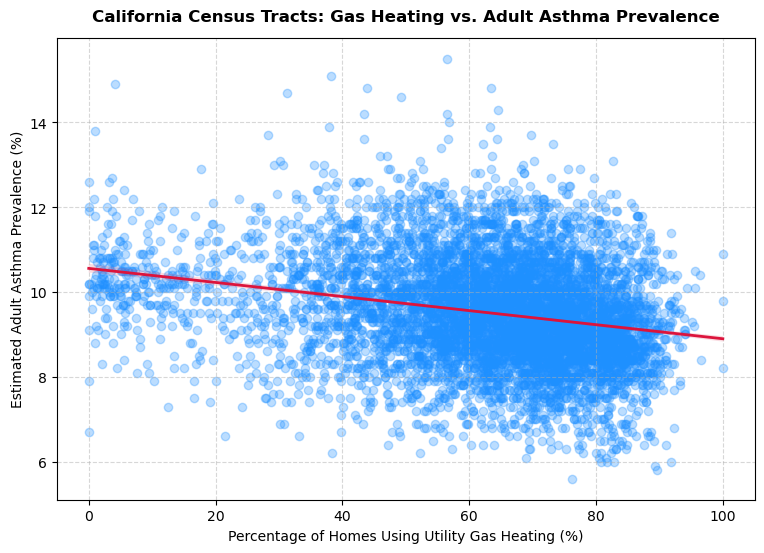

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# 1. Load your saved merged dataset
df = pd.read_csv("ca_heating_vs_asthma_tracts.csv")

# Ensure numeric types for calculations
df['total_units'] = pd.to_numeric(df['total_units'], errors='coerce')
df['utility_gas_units'] = pd.to_numeric(df['utility_gas_units'], errors='coerce')
df['CASTHMA_CrudePrev'] = pd.to_numeric(df['CASTHMA_CrudePrev'], errors='coerce')

# Drop rows with missing values or zero total units to prevent errors
df = df.dropna(subset=['total_units', 'utility_gas_units', 'CASTHMA_CrudePrev'])
df = df[df['total_units'] > 0]

# 2. Calculate the percentage of homes using utility gas per tract
df['pct_utility_gas'] = (df['utility_gas_units'] / df['total_units']) * 100

# 3. Calculate Pearson correlation coefficient and p-value
corr, p_value = pearsonr(df['pct_utility_gas'], df['CASTHMA_CrudePrev'])
print(f"--- Statistical Summary ---")
print(f"Pearson Correlation Coefficient (r): {corr:.3f}")
print(f"P-value: {p_value:.4e}\n")

# 4. Create a scatter plot with a regression trendline
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df, 
    x='pct_utility_gas', 
    y='CASTHMA_CrudePrev',
    scatter_kws={'alpha': 0.3, 'color': 'dodgerblue'}, # semi-transparent points to show density
    line_kws={'color': 'crimson', 'linewidth': 2}      # trend line
)

plt.title('California Census Tracts: Gas Heating vs. Adult Asthma Prevalence', fontsize=12, pad=12, fontweight='bold')
plt.xlabel('Percentage of Homes Using Utility Gas Heating (%)', fontsize=10)
plt.ylabel('Estimated Adult Asthma Prevalence (%)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

### Analysis Scratch Work

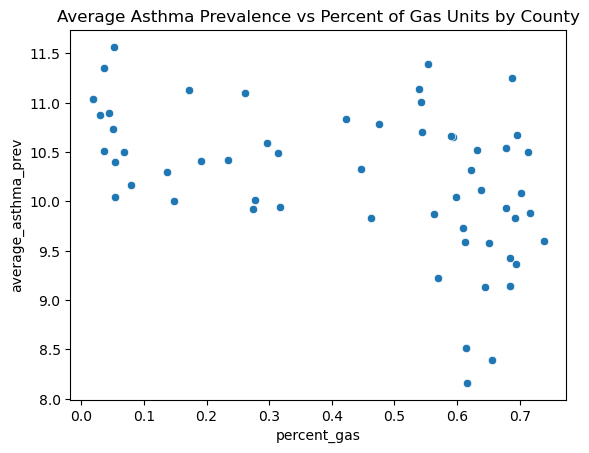

In [35]:
#create a new column with just the county names
df['County'] = df['NAME'].str.extract(r';\s*([^;]+?)\s+County')[0]

df.sample(10)

#create a df grouped by county, showing the total counts for different units and the average asthma 
#prevalence by county
grouped_df = df.groupby('County').agg({
    'total_units' : 'sum',
    'utility_gas_units' : 'sum',
    'electricity_units' : 'sum',
    'CASTHMA_CrudePrev' : 'mean'
})

grouped_df = grouped_df.rename(columns = {'CASTHMA_CrudePrev' : 'average_asthma_prev'})
grouped_df['percent_gas'] = grouped_df['utility_gas_units']/grouped_df['total_units']
grouped_df.sort_values(by = ['percent_gas'], ascending = False)

sns.scatterplot(data = grouped_df, x = 'percent_gas', y = 'average_asthma_prev')
plt.title('Average Asthma Prevalence vs Percent of Gas Units by County');

### Reflections

No clear correlation present. Most likely due to confounding factors for asthma rates. 

Confounding factors brainstorming: 
* local air quality/air pollution rates
* county average income levels
* access to healthcare/insurance 

I think the first two are the biggest priorities => next step is to find and load in data for local air quality/air pollution rates and average income levels.

### Local Air Quality and Income Data

#### Chosen datasets: 

* CalEnviroScreen
  * downloadable dataset created by California Office of Environmental Health Hazard Assessment. 
  * provides a pullution burden score and specific indicators for PM 2.5 concentrations and diesel particulate matter aggregated by county
  * https://data.ca.gov/@california-office-of-environmental-health-hazard-assessment/calenviroscreen-5-01 
  * https://data.ca.gov/@california-office-of-environmental-health-hazard-assessment/calenviroscreen-5-0/r/c4e277e0-cf23-4a8f-b07e-c8544c5d3d2b


* US Census Bureau - American Community Survey (ACS)
  * contains data on median income in the past 12 months at the census tract and county levels

#### Loading in income data from Census

In [57]:
import requests

def load_census_acs_data(api_key, year="2023"):
    print("Fetching ACS data from U.S. Census Bureau API...")
    
    base_url = f"https://api.census.gov/data/{year}/acs/acs5"
    
    variables = {
        "NAME": "Name",
        "B19013_001E": "median_income",
        "B01001_001E": "total_population"
    }
    
    get_vars = ",".join(variables.keys())
    url = f"{base_url}?get={get_vars}&for=county:*&in=state:06&key={api_key}"
    
    response = requests.get(url)
    response.raise_for_status()
    data = response.json()
    
    header = data[0]
    rows = data[1:]
    df_acs = pd.DataFrame(rows, columns=header)
    
    #rename columns to variable names
    df_acs = df_acs.rename(columns=variables)
    
    numeric_cols = ["median_income", "total_population"]
    for col in numeric_cols:
        df_acs[col] = pd.to_numeric(df_acs[col], errors="coerce")
        
    print(f"Loaded ACS data for {df_acs.shape[0]} California counties.")
    return df_acs

income_df = load_census_acs_data("f33094cc5c703bb7fc5d634e5469bbd5e3781c5d")
income_df.head(10)

Fetching ACS data from U.S. Census Bureau API...
Loaded ACS data for 58 California counties.


,Name,median_income,total_population,state,county
0,"Alameda County, California",126240,1651949,06,001
1,"Alpine County, California",110781,1695,06,003
2,"Amador County, California",81526,41029,06,005
3,"Butte County, California",68574,209470,06,007
4,"Calaveras County, California",79877,45995,06,009
5,"Colusa County, California",75149,21895,06,011
6,"Contra Costa County, California",125727,1161458,06,013
7,"Del Norte County, California",66780,27293,06,015
8,"El Dorado County, California",106190,192299,06,017
9,"Fresno County, California",71434,1012152,06,019


In [58]:
import pandas as pd
import requests

def load_ces_via_ckan():    
    #resource ID provided in the API endpoint
    resource_id = "c4e277e0-cf23-4a8f-b07e-c8544c5d3d2b"
    
    #set limit to 10,000 to capture all rows in one fetch
    url = f"https://publish.data.ca.gov/api/3/action/datastore_search?resource_id={resource_id}&limit=10000"
    
    response = requests.get(url)
    response.raise_for_status()
    
    #get the records list from the JSON response
    data = response.json()
    records = data['result']['records']
    
    #convert directly into a pandas DataFrame
    pollution_df = pd.DataFrame(records)
    
    print(f"Successfully loaded {pollution_df.shape[0]} rows and {pollution_df.shape[1]} columns.")
    return df_ces

#run the function
pollution_df = load_ces_via_ckan()
pollution_df.head()

Successfully loaded 9106 rows and 71 columns.


,_id,tract,zipcode,approx_loc,county,region,ACS2024Pop,CIscore,CIscoreP,ozone,...,pop_und10,pop_10_64,pop_ov64,hisp,white,black,amind,asian,pacisl,othmult
0,1,6001400100,94720,Berkeley,Alameda,Bay Area,3132,7.442022,5.767741,0.028579,...,10.86,59.00,30.14,6.83,65.49,4.98,0.00,17.37,0.0,5.33
1,2,6001400200,94618,Oakland,Alameda,Bay Area,2203,10.516528,13.096424,0.027992,...,11.35,63.78,24.88,9.17,64.82,2.04,0.86,12.44,0.0,10.67
2,3,6001400300,94618,Oakland,Alameda,Bay Area,5990,11.384174,15.365881,0.027761,...,7.91,73.61,18.48,9.53,58.20,8.65,0.37,7.93,0.0,15.33
3,4,6001400400,94609,Oakland,Alameda,Bay Area,4399,8.779157,8.767851,0.027934,...,15.07,69.15,15.78,11.57,61.63,7.66,0.00,11.75,0.0,7.39
4,5,6001400500,94609,Oakland,Alameda,Bay Area,3579,19.681362,37.639765,0.027894,...,10.62,71.67,17.71,17.77,45.99,21.15,0.08,7.35,0.2,7.46


In [60]:
pollution_df.columns

Index(['_id', 'tract', 'zipcode', 'approx_loc', 'county', 'region',
       'ACS2024Pop', 'CIscore', 'CIscoreP', 'ozone', 'ozoneP', 'pm', 'pmP',
       'diesel', 'dieselP', 'pest', 'pestP', 'RSEIhaz', 'RSEIhazP', 'traffic',
       'trafficP', 'drink', 'drinkP', 'lead', 'leadP', 'cleanups', 'cleanupsP',
       'gwthreats', 'gwthreatsP', 'haz', 'hazP', 'iwb', 'iwbP', 'swis',
       'swisP', 'SmATS', 'SmATSP', 'Pollution', 'PollutionS', 'PollutionP',
       'asthma', 'asthmaP', 'lbw', 'lbwP', 'cvd', 'cvdP', 'diabetes',
       'diabetesP', 'edu', 'eduP', 'ling', 'lingP', 'pov', 'povP', 'unemp',
       'unempP', 'housingB', 'housingBP', 'PopChar', 'PopCharSco', 'PopCharP',
       'pop_und10', 'pop_10_64', 'pop_ov64', 'hisp', 'white', 'black', 'amind',
       'asian', 'pacisl', 'othmult'],
      dtype='object')

This document provides details on all of these variables (column names): https://oehha.ca.gov/sites/default/files/media/2026-01/calenviroscreen50techreportd12226.pdf#:~:text=o%20Impaired%20Waters.%20o%20Small%20Air%20Toxic,Other%20sensitive%20individuals%20include%20those%20with%20physiological.

I think the most important ones for this research are: 
* 'ozone': mean summer ozone concentration
* 'pm': annual mean concentrations of PM2.5
* 'diesel': diesel particulate matter emissions from on-road and off-road sources
* 'RSEIhaz': risk-screening environmental indicators (RSEI) for toxic air releases from industrial facilities
* 'traffic': traffic density (vehicle miles on road / road length)
* 'pov': percent of population living below the federal poverty line
* 'housingB': housing-burdened low-income households 

In [65]:
pollution_df2 = pollution_df[['tract','county','ozone', 'pm', 'diesel', 'RSEIhaz', 'traffic', 'pov', 'housingB']]
pollution_df2

,tract,county,ozone,pm,diesel,RSEIhaz,traffic,pov,housingB
0,6001400100,Alameda,0.028579,6.882156,0.097242,575.738993,539.417,7.367072,7.636364
1,6001400200,Alameda,0.027992,6.950723,0.181734,577.368001,1229.853,10.939628,7.314286
2,6001400300,Alameda,0.027761,7.120572,0.168340,560.140666,1244.499,11.475410,8.333333
3,6001400400,Alameda,0.027934,6.916525,0.171107,600.389008,975.612,17.392311,11.590909
4,6001400500,Alameda,0.027894,6.916525,0.144948,626.021667,321.162,26.560313,27.619048
...,...,...,...,...,...,...,...,...,...
9101,6115040902,Yuba,0.046584,7.674943,0.015820,0.210066,224.501,47.527812,26.875000
9102,6115041001,Yuba,0.046980,7.824756,0.023762,0.122459,209.438,16.657175,20.805369
9103,6115041002,Yuba,0.047606,6.870307,0.003012,0.055273,134.890,15.991272,15.172414
9104,6115041101,Yuba,0.048377,6.171787,0.002104,0.000251,43.721,54.184458,19.710145


### Joining Datasets

I now want to create a dataset that has information on percent of gas units by county, asthma prevalance by county, and information about pollution and income levels. This involves combining the following datasets: 
* grouped_df (data on percent of gas units grouped by county) 
* income_df (data on median income levels by county)
* pollution_df2 (data on pollution levels by county)

In [79]:
grouped_df.head(10)

,level_0,index,County,total_units,utility_gas_units,electricity_units,average_asthma_prev,percent_gas
0,0,0,Alameda,542336,370988,144450,9.143695,0.684056
1,1,1,Alpine,435,19,38,10.900000,0.043678
2,2,2,Amador,13837,3828,3660,10.012500,0.276650
3,3,3,Butte,76495,36347,25657,10.787500,0.475155
4,4,4,Calaveras,8322,1134,1530,10.300000,0.136265
5,5,5,Colusa,5547,2477,1960,10.325000,0.446548
6,6,6,Contra Costa,307809,210907,80556,9.423429,0.685188
7,7,7,Del Norte,7108,258,4416,11.350000,0.036297
8,8,8,El Dorado,53501,16970,11167,9.940625,0.317190
9,9,9,Fresno,255654,139091,93509,10.708929,0.544060


In [98]:
income_df.rename(columns = {'Name': 'County', 'county':'county_ID'})
#fix the county data so that it just has the name, not ____ County, California attached as well
income_df['County'] = df['County'].str.replace(r'\s+County,\s+California$', '', regex=True).str.strip()
income_df

,Name,median_income,total_population,state,county,County
0,"Alameda County, California",126240,1651949,06,001,Alameda
1,"Alpine County, California",110781,1695,06,003,Alameda
2,"Amador County, California",81526,41029,06,005,Alameda
3,"Butte County, California",68574,209470,06,007,Alameda
4,"Calaveras County, California",79877,45995,06,009,Alameda
5,"Colusa County, California",75149,21895,06,011,Alameda
6,"Contra Costa County, California",125727,1161458,06,013,Alameda
7,"Del Norte County, California",66780,27293,06,015,Alameda
8,"El Dorado County, California",106190,192299,06,017,Alameda
9,"Fresno County, California",71434,1012152,06,019,Alameda


In [92]:
pollution_df2 = pollution_df2.rename(columns={'county': 'County'})
pollution_df2.groupby('County')[['ozone', 'pm', 'diesel', 'RSEIhaz', 'traffic', 'pov', 'housingB']].mean().reset_index()


,County,ozone,pm,diesel,RSEIhaz,traffic,pov,housingB
0,Alameda,0.031070,7.296395,0.172783,628.568885,728.071164,20.539172,15.902388
1,Alpine,0.050362,5.923498,0.000736,4.882403,88.834000,21.967822,6.436782
2,Amador,0.048083,6.695640,0.007665,13.644618,169.636000,21.023834,13.394650
3,Butte,0.048868,7.113177,0.063271,3.533367,274.487574,36.981732,16.031481
4,Calaveras,0.049168,6.490259,0.006458,25.642134,113.404357,26.655333,14.820530
5,Colusa,0.043313,7.026412,0.016924,5.627138,236.484000,32.145633,10.536004
6,Contra Costa,0.034758,7.385883,0.087911,821.080908,582.983353,18.180847,15.164594
7,Del Norte,0.033954,6.680081,0.018124,0.658448,134.233750,37.750249,11.007453
8,El Dorado,0.049625,5.958311,0.023835,19.673793,293.923245,18.821524,14.406310
9,Fresno,0.055901,10.543416,0.088699,2094.371475,388.544876,40.454513,17.118811


Now that all of the datasets are cleaned up for the merge, we can complete the merge.

In [102]:
#merge all three datasets on County

#merge grouped_df and income_df on 'County', then merge that with pollution_df2 also on 'County'
merged_df = grouped_df.merge(income_df, on='County', how='inner').merge(pollution_df2, on='County', how='inner')

merged_df

,level_0,index,County,total_units,utility_gas_units,electricity_units,average_asthma_prev,percent_gas,Name,median_income,...,state,county,tract,ozone,pm,diesel,RSEIhaz,traffic,pov,housingB
0,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Alameda County, California",126240,...,06,001,6001400100,0.028579,6.882156,0.097242,575.738993,539.417,7.367072,7.636364
1,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Alameda County, California",126240,...,06,001,6001400200,0.027992,6.950723,0.181734,577.368001,1229.853,10.939628,7.314286
2,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Alameda County, California",126240,...,06,001,6001400300,0.027761,7.120572,0.168340,560.140666,1244.499,11.475410,8.333333
3,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Alameda County, California",126240,...,06,001,6001400400,0.027934,6.916525,0.171107,600.389008,975.612,17.392311,11.590909
4,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Alameda County, California",126240,...,06,001,6001400500,0.027894,6.916525,0.144948,626.021667,321.162,26.560313,27.619048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21919,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Yuba County, California",73313,...,06,115,6001451704,0.041476,6.903897,0.022894,326.009664,140.079,20.552147,12.651757
21920,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Yuba County, California",73313,...,06,115,6001981900,0.027119,7.487117,1.115605,417.619339,1088.329,0.000000,0.000000
21921,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Yuba County, California",73313,...,06,115,6001982000,0.026928,7.482230,1.242814,456.597341,846.317,0.000000,0.000000
21922,0,0,Alameda,542336,370988,144450,9.143695,0.684056,"Yuba County, California",73313,...,06,115,6001982100,0.028591,6.785781,0.213143,721.145671,386.385,35.483871,50.000000


In [104]:
#check if we can drop any unnecessary columns

merged_df.columns

Index(['level_0', 'index', 'County', 'total_units', 'utility_gas_units',
       'electricity_units', 'average_asthma_prev', 'percent_gas', 'Name',
       'median_income', 'total_population', 'state', 'county', 'tract',
       'ozone', 'pm', 'diesel', 'RSEIhaz', 'traffic', 'pov', 'housingB'],
      dtype='object')

In [113]:
merged_df

,County,total_units,utility_gas_units,electricity_units,average_asthma_prev,percent_gas,median_income,total_population,state,county,tract,ozone,pm,diesel,RSEIhaz,traffic,pov,housingB
0,Alameda,542336,370988,144450,9.143695,0.684056,126240,1651949,06,001,6001400100,0.028579,6.882156,0.097242,575.738993,539.417,7.367072,7.636364
1,Alameda,542336,370988,144450,9.143695,0.684056,126240,1651949,06,001,6001400200,0.027992,6.950723,0.181734,577.368001,1229.853,10.939628,7.314286
2,Alameda,542336,370988,144450,9.143695,0.684056,126240,1651949,06,001,6001400300,0.027761,7.120572,0.168340,560.140666,1244.499,11.475410,8.333333
3,Alameda,542336,370988,144450,9.143695,0.684056,126240,1651949,06,001,6001400400,0.027934,6.916525,0.171107,600.389008,975.612,17.392311,11.590909
4,Alameda,542336,370988,144450,9.143695,0.684056,126240,1651949,06,001,6001400500,0.027894,6.916525,0.144948,626.021667,321.162,26.560313,27.619048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21919,Alameda,542336,370988,144450,9.143695,0.684056,73313,83079,06,115,6001451704,0.041476,6.903897,0.022894,326.009664,140.079,20.552147,12.651757
21920,Alameda,542336,370988,144450,9.143695,0.684056,73313,83079,06,115,6001981900,0.027119,7.487117,1.115605,417.619339,1088.329,0.000000,0.000000
21921,Alameda,542336,370988,144450,9.143695,0.684056,73313,83079,06,115,6001982000,0.026928,7.482230,1.242814,456.597341,846.317,0.000000,0.000000
21922,Alameda,542336,370988,144450,9.143695,0.684056,73313,83079,06,115,6001982100,0.028591,6.785781,0.213143,721.145671,386.385,35.483871,50.000000
